#ML7. Clustering algorithms

## 1. Ответы на вопросы:

1.1 Еще один метод инициализации для метода K-means: Grid-Density Initialization (Инициализация на основе плотности сетки)

Пространство признаков разбивается на равномерную сетку (grid).
Подсчитывается количество точек в каждой ячейке сетки.
Выбираются
$K$ ячеек с наибольшей плотностью.
Начальные центроиды инициализируются как центры масс (средние значения) точек внутри этих
$K$ ячеек.


**Метод Forgy** (Случайные точки). Случайным образом выбираются k точек из датасета, и их координаты становятся начальными центрами.

Плюсы:
- Быстрая и простая инициализация
- Хорошо работает на больших данных

Минусы:
- Возможно "кучкование" в плотных областях
- Чувствительность к выбросам

**Метод Random Partition** (случайное разбиение) начинается с случайного распределения всех точек данных по кластерам.

Плюсы:
- Лучшая стабильность сходимости

Минусы:
- Центроиды могут быть далеко от реальных точек
- Медленнее Forgy на больших данных


1.2. Алгоритм KNN для каждого нового объекта ищет в обучающей выборке K ближайших соседей по некоторой метрике. На больших данных поиск всех соседей перебором становится очень дорогим по времени

Ускорение через кластеризацию:
1. Разбиваем обучающую выборку на кластеры (например, с помощью K-Means).
2. При поиске ближайших соседей для нового объекта:
    - Сначала определяем, к какому кластеру он ближе всего (по центроиду).
    - Затем ищем ближайших соседей только внутри этого кластера или нескольких ближайших кластеров.

## 2. Введение: предварительная обработка данных


In [ ]:
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.mixture import GaussianMixture
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, silhouette_score
from sklearn.model_selection import GridSearchCV
from collections import Counter
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN

In [ ]:
data = pd.read_json("train.json")
train, test = train_test_split(data, test_size=0.2, random_state=21)
train = train.reset_index(drop=True)
test = test.reset_index(drop=True)

def replace_features(x):
    x = str(x)
    return x.replace('"', '').replace('[', '').replace(']', '').replace("'", '').replace(' ', '')

train['replace_features'] = train['features'].apply(replace_features)
test['replace_features'] = test['features'].apply(replace_features)

features_list = []
for feature in train['replace_features']:
    for f in feature.split(','):
        features_list.append(f)

cnt = Counter(features_list)
cnt.most_common(20)

most_common_features = [i[0] for i in cnt.most_common(21) if i[0] != '']
print(f"Новые признаки:\n")
print(most_common_features)

for feature in most_common_features:
    train[feature] = train['replace_features'].str.contains(feature).astype('int')
    test[feature] = test['replace_features'].str.contains(feature).astype('int')

interest_level_map = {'low': 0, 'medium': 1, 'high': 2}
train['interest_level_encoded'] = train['interest_level'].map(interest_level_map)
test['interest_level_encoded'] = test['interest_level'].map(interest_level_map)

features = ['bathrooms', 'bedrooms', 'longitude', 'latitude', 'interest_level_encoded'] + most_common_features
target = 'price'

train_X = train[features]
train_y = train[target]

test_X = test[features]
test_y = test[target]

print(f"Train shape: {train_X.shape}")
print(f"Test shape: {test_X.shape}")

Новые признаки:

['Elevator', 'CatsAllowed', 'HardwoodFloors', 'DogsAllowed', 'Doorman', 'Dishwasher', 'NoFee', 'LaundryinBuilding', 'FitnessCenter', 'Pre-War', 'LaundryinUnit', 'RoofDeck', 'OutdoorSpace', 'DiningRoom', 'HighSpeedInternet', 'Balcony', 'SwimmingPool', 'LaundryInBuilding', 'NewConstruction', 'Terrace']
Train shape: (39481, 25)
Test shape: (9871, 25)


## 3. KMeans


In [ ]:
class MyKMeans:
    def __init__(self, n_clusters=10, n_init=10, max_iter=300, tol=1e-4, random_state=None):
        self.n_clusters = n_clusters
        self.n_init = n_init # кол-во запусков
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state

        self.labels_ = None
        self.cluster_centers_ = None
        self.inertia_ = None
        self.n_iter_ = None

    def _compute_distances(self, X, centroids):
        return np.linalg.norm(X[:, None] - centroids, axis=2)

    def _compute_inertia(self, X, labels, centroids):
        return np.sum((X - centroids[labels]) ** 2)

    def _fit_single(self, X, n_samples):
        initial_indices = np.random.choice(n_samples, self.n_clusters, replace=False)
        centroids = X[initial_indices].copy()

        n_iter = 0
        for n_iter in range(self.max_iter):
            distances = self._compute_distances(X, centroids)
            labels = np.argmin(distances, axis=1)

            new_centroids = np.array([
                X[labels == i].mean(axis=0) if np.any(labels == i) else centroids[i]
                for i in range(self.n_clusters)
            ])

            if np.linalg.norm(new_centroids - centroids) < self.tol:
                break

            centroids = new_centroids

        inertia = self._compute_inertia(X, labels, centroids)

        return labels, centroids, inertia, n_iter + 1

    def fit(self, X):
        X = np.asarray(X)
        n_samples = X.shape[0]

        if self.random_state is not None:
            np.random.seed(self.random_state)

        best_inertia = np.inf
        best_labels = None
        best_centroids = None
        best_n_iter = None

        for init_no in range(self.n_init):
            labels, centroids, inertia, n_iter = self._fit_single(X, n_samples)

            if inertia < best_inertia:
                best_inertia = inertia
                best_labels = labels.copy()
                best_centroids = centroids.copy()
                best_n_iter = n_iter

        self.labels_ = best_labels
        self.cluster_centers_ = best_centroids
        self.inertia_ = best_inertia
        self.n_iter_ = best_n_iter

        return self

    def predict(self, X):
        if self.cluster_centers_ is None:
            raise ValueError("Модель не обучена.")

        X = np.asarray(X)
        distances = self._compute_distances(X, self.cluster_centers_)
        labels = np.argmin(distances, axis=1)

        return labels

    def fit_predict(self, X):
        self.fit(X)
        return self.labels_

    def score(self, X):
        X = np.asarray(X)
        labels = self.predict(X)
        inertia = self._compute_inertia(X, labels, self.cluster_centers_)
        return -inertia

In [ ]:
my_kmeans = MyKMeans(n_clusters=30, n_init=10, max_iter=300, random_state=21)
my_kmeans.fit(train[['latitude', 'longitude']])

train_pred_my_kmeans = my_kmeans.predict(train[['latitude', 'longitude']])
test_pred_my_kmeans = my_kmeans.predict(test[['latitude', 'longitude']])

print(f"Результаты собственной модели test:\n")
print("Distortion (Inertia):", my_kmeans.inertia_)

my_sil_score = silhouette_score(test[['latitude', 'longitude']], test_pred_my_kmeans)
print("Silhouette score:", my_sil_score)


Результаты собственной модели test:

Distortion (Inertia): 747.8549461615211
Silhouette score: 0.4210995123070669


In [ ]:
k_means = KMeans(n_clusters=30, n_init=10, random_state=21)
k_means.fit(train[['latitude', 'longitude']])

train_pred = k_means.predict(train[['latitude', 'longitude']])
test_pred = k_means.predict(test[['latitude', 'longitude']])

print(f"Результаты модели sklearn:\n")
print("Distortion (Inertia):", k_means.inertia_)

sil_score = silhouette_score(test[['latitude', 'longitude']], test_pred)
print("Silhouette score:", sil_score)

Результаты модели sklearn:

Distortion (Inertia): 7.003385301937211
Silhouette score: 0.4399687050351439


In [ ]:
def show_scatterplot(x, y, hue):
    plt.scatter(x, y, c=hue, s=20, alpha=0.7, cmap='tab10')
    plt.xlim(-74.05, -73.85)
    plt.ylim(40.65, 40.85)
    plt.show()

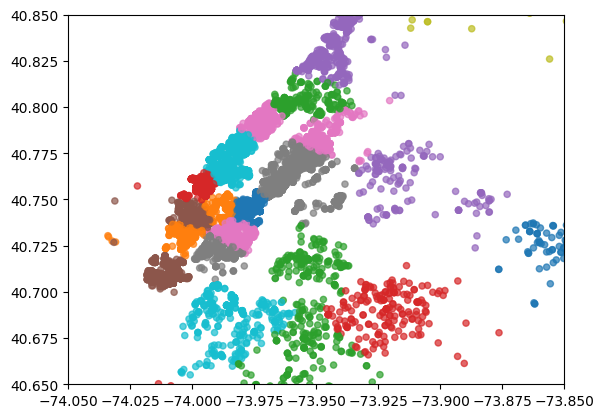

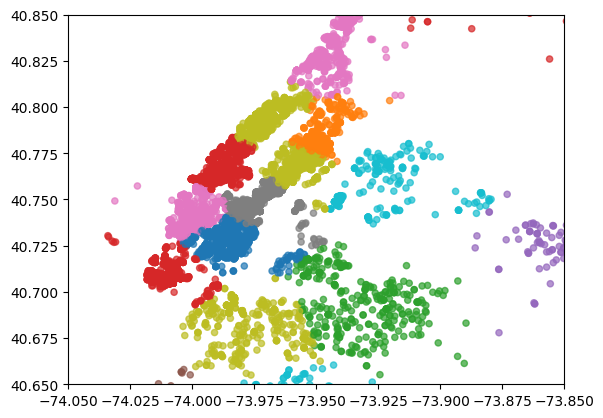

In [ ]:
show_scatterplot(x=test['longitude'], y=test['latitude'], hue=test_pred_my_kmeans)
show_scatterplot(x=test['longitude'], y=test['latitude'], hue=test_pred)

In [ ]:
mms = MinMaxScaler()
lasso = Lasso(random_state=21)

df_metrics = pd.DataFrame()
def print_metrics(train, test, model):
    global df_metrics
    train_x_mms = mms.fit_transform(train)
    test_x_mms = mms.transform(test)

    lasso.fit(train_x_mms, train_y)

    train_predict = lasso.predict(train_x_mms)
    test_predict = lasso.predict(test_x_mms)

    metrics_dict = {
        'Model': model,
        'Train MAE': mean_absolute_error(train_y, train_predict),
        'Test MAE': mean_absolute_error(test_y, test_predict),
        'Train RMSE': mean_squared_error(train_y, train_predict)**0.5,
        'Test RMSE': mean_squared_error(test_y, test_predict)**0.5,
        'Train R2': r2_score(train_y, train_predict),
        'Test R2': r2_score(test_y, test_predict)
    }

    for k, v in metrics_dict.items():
        print(f"{k}: {v}")

    df_metrics = pd.concat([df_metrics, pd.DataFrame([metrics_dict])], ignore_index=True)

    return lasso.coef_

In [ ]:
coef_base = print_metrics(train_X, test_X, 'Base Lasso')

Model: Base Lasso
Train MAE: 1224.7891558312429
Test MAE: 1023.124293063516
Train RMSE: 24565.197312518747
Test RMSE: 2173.420621189107
Train R2: 0.005666493077047363
Test R2: 0.33840644950871623


In [ ]:
train_cluster_X = train_X.copy()
train_cluster_X['cluster'] = train_pred
test_cluster_X = test_X.copy()
test_cluster_X['cluster'] = test_pred

coef_new = print_metrics(train_cluster_X, test_cluster_X, 'KMeans Lasso')

Model: KMeans Lasso
Train MAE: 1223.664108357759
Test MAE: 1021.2394587816843
Train RMSE: 24565.06746421552
Test RMSE: 2172.5544316645473
Train R2: 0.005677004873540281
Test R2: 0.3389336840470768


In [ ]:
features_cluster = features + ['cluster']
feature_importance = pd.DataFrame({
    'feature': features_cluster,
    'coef': abs(coef_new)
})
feature_importance = feature_importance.sort_values('coef', ascending=False)
feature_importance

,feature,coef
0,bathrooms,20164.142428
1,bedrooms,4943.023227
9,Doorman,1680.050301
4,interest_level_encoded,1071.483025
22,LaundryInBuilding,692.100060
12,LaundryinBuilding,657.405613
13,FitnessCenter,621.860948
5,Elevator,593.946935
15,LaundryinUnit,536.047733
8,DogsAllowed,491.884215


## 4. DBSCAN


In [ ]:
from collections import deque
from sklearn.neighbors import BallTree
import numpy as np

class MyDBSCAN:
    def __init__(self, eps=0.5, min_samples=5, metric='euclidean'):
        self.eps = eps
        self.min_samples = min_samples
        self.metric = metric

        self.labels_ = None
        self.core_sample_indices_ = None
        self.n_clusters_ = None
        self.n_noise_ = None
        self._tree = None
        self._X = None

    def _query_neighbors(self, point):
        return self._tree.query_radius([point], r=self.eps)[0]

    def _expand_cluster(self, i, neighbors, cluster_id, labels, visited):
        queue = deque(neighbors)

        while queue:
            j = queue.popleft()

            if not visited[j]:
                visited[j] = True
                local_neighbors = self._query_neighbors(self._X[j])

                if len(local_neighbors) >= self.min_samples:
                    queue.extend(local_neighbors)

            if labels[j] == -1:
                labels[j] = cluster_id

    def fit(self, X):
        X = np.asarray(X)
        n = X.shape[0]

        self._X = X
        self._tree = BallTree(X, metric=self.metric)
        labels = np.full(n, -1, dtype=int)
        visited = np.zeros(n, dtype=bool)
        core_sample_indices = []

        cluster_id = 0

        for i in range(n):
            if visited[i]:
                continue

            visited[i] = True
            neighbors = self._query_neighbors(X[i])

            if len(neighbors) < self.min_samples:
                labels[i] = -1
            else:
                labels[i] = cluster_id
                core_sample_indices.append(i)

                self._expand_cluster(i, neighbors, cluster_id, labels, visited)

                cluster_id += 1

        self.labels_ = labels
        self.core_sample_indices_ = np.array(core_sample_indices, dtype=int)
        self.n_clusters_ = cluster_id
        self.n_noise_ = np.sum(labels == -1)

        return self

    def fit_predict(self, X):
        self.fit(X)
        return self.labels_

    def predict(self, X):
        if self.labels_ is None:
            raise ValueError("Модель не обучена.")

        X = np.asarray(X)
        n_new = X.shape[0]
        labels = np.full(n_new, -1, dtype=int)

        for i in range(n_new):
            min_dist = np.inf
            best_cluster = -1

            for core_idx in self.core_sample_indices_:
                dist = np.linalg.norm(X[i] - self._X[core_idx])
                if dist < self.eps and dist < min_dist:
                    min_dist = dist
                    best_cluster = self.labels_[core_idx]

            labels[i] = best_cluster

        return labels


Коэффициент силуэта (своя реализация): -0.17055641656461612
Коэффициент силуэта (sklearn): -0.17055641656461612


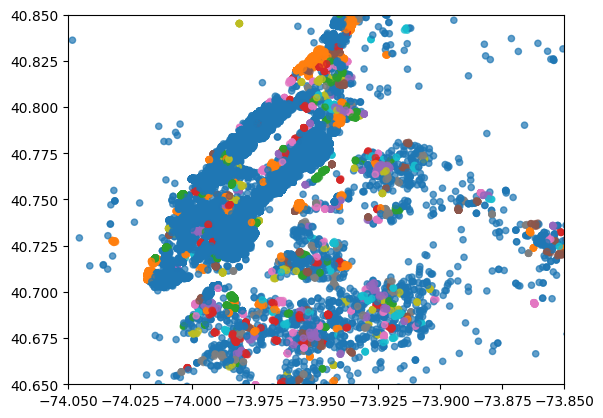

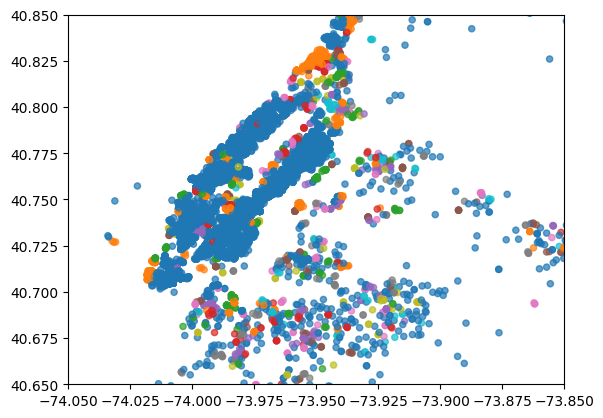

Model: DBSCAN Lasso
Train MAE: 1218.4568500396988
Test MAE: 1015.1123312253725
Train RMSE: 24564.301111113502
Test RMSE: 2168.5634039815322
Train R2: 0.005739043427009816
Test R2: 0.34136023832960205


,feature,coef
0,bathrooms,19965.260299
1,bedrooms,5036.258564
9,Doorman,1632.190398
25,cluster,1221.161613
4,interest_level_encoded,1047.915023
22,LaundryInBuilding,704.628090
12,LaundryinBuilding,659.155847
13,FitnessCenter,617.633792
5,Elevator,587.575052
15,LaundryinUnit,544.021712


In [ ]:
full_df = pd.concat([train, test]).reset_index(drop=True)
X_coords = full_df[['latitude', 'longitude']].values
# своя
mydbscan = MyDBSCAN(eps=0.001, min_samples=5, metric='euclidean')
my_dbscan_clusters = mydbscan.fit_predict(X_coords)

train_pred_my_dbscan = my_dbscan_clusters[:train.shape[0]]
test_pred_my_dbscan = my_dbscan_clusters[train.shape[0]:]

n_clusters_my = len(set(my_dbscan_clusters)) - (1 if -1 in my_dbscan_clusters else 0)
if n_clusters_my >= 2:
    sil_score_my = silhouette_score(X_coords, my_dbscan_clusters)
    print("Коэффициент силуэта (своя реализация):", sil_score_my)

# === SKLEARN РЕАЛИЗАЦИЯ ===
dbscan = DBSCAN(eps=0.001, min_samples=5)
pred = dbscan.fit_predict(full_df[['latitude', 'longitude']])

train_pred_dbscan = pred[:train.shape[0]]
test_pred_dbscan = pred[train.shape[0]:]


sil_score_sklearn = silhouette_score(full_df[['latitude', 'longitude']], dbscan.labels_)
print("Коэффициент силуэта (sklearn):", sil_score_sklearn)


show_scatterplot(x=train['longitude'], y=train['latitude'], hue=train_pred_dbscan)
show_scatterplot(x=test['longitude'], y=test['latitude'], hue=test_pred_dbscan)


train_dbscan_X = train_X.copy()
train_dbscan_X['cluster'] = train_pred_dbscan

test_dbscan_X = test_X.copy()
test_dbscan_X['cluster'] = test_pred_dbscan

coef_dbscan = print_metrics(train_dbscan_X, test_dbscan_X, 'DBSCAN Lasso')

features_cluster = features + ['cluster']
feature_importance_dbscan = pd.DataFrame({
    'feature': features_cluster,
    'coef': abs(coef_dbscan)
})
feature_importance_dbscan = feature_importance_dbscan.sort_values('coef', ascending=False)
feature_importance_dbscan

## 5. AgglomerativeClustering


**Agglomerative Clustering** (агломеративная кластеризация) — это иерархический алгоритм кластеризации, который строит древовидную структуру (дендрограмму) вложенных кластеров.
В отличие от K-Means, который даёт "плоское" разбиение, агломеративная кластеризация показывает иерархию сходства между объектами — от отдельных точек до одного общего кластера.

Пошаговое описание:

**Инициализация**:

1. Каждая из $N$ точек — отдельный кластер (всего $N$ кластеров)


2. Повторяем, пока не останется нужное число кластеров $K$:

а) Находим два самых близких кластера по выбранной метрике

б) Объединяем их в один кластер.

3. Результат: дендрограмма + финальное разбиение на K кластеров

Коэффициент силуэта: 0.4481035564841398


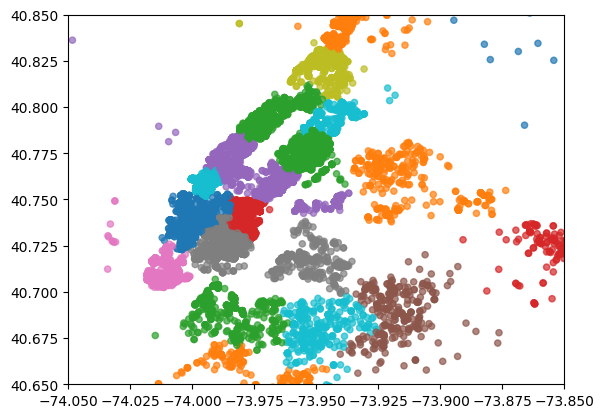

In [ ]:
data_X = pd.concat([train_X, test_X]).reset_index(drop=True)
data_y = pd.concat([train_y, test_y]).reset_index(drop=True)
sample_idx = data_X.sample(20000, random_state=21).index
sample_data = data_X.loc[sample_idx]
sample_target = data_y.loc[sample_idx]

sample_cluster = full_df.loc[sample_idx]
sample = sample_cluster[['latitude', 'longitude']]
ac = AgglomerativeClustering(n_clusters=30)
ac.fit(sample)
labels = ac.labels_

sil_score = silhouette_score(sample, labels)
print("Коэффициент силуэта:", sil_score)
show_scatterplot(x=sample['longitude'], y=sample['latitude'], hue=labels)

In [ ]:
sample_data['cluster'] = labels
ac_train_X, ac_test_X, ac_train_y, ac_test_y = train_test_split(
    sample_data, sample_target, test_size=0.2, random_state=21
)

train_x_mms = mms.fit_transform(ac_train_X)
test_x_mms = mms.transform(ac_test_X)

lasso.fit(train_x_mms, ac_train_y)
ac_coef = lasso.coef_

train_predict = lasso.predict(train_x_mms)
test_predict = lasso.predict(test_x_mms)

metrics_dict = {
    'Model': 'AgglomerativeClustering Lasso',
    'Train MAE': mean_absolute_error(ac_train_y, train_predict),
    'Test MAE': mean_absolute_error(ac_test_y, test_predict),
    'Train RMSE': mean_squared_error(ac_train_y, train_predict)**0.5,
    'Test RMSE': mean_squared_error(ac_test_y, test_predict)**0.5,
    'Train R2': r2_score(ac_train_y, train_predict),
    'Test R2': r2_score(ac_test_y, test_predict)
}

for k, v in metrics_dict.items():
    print(f"{k}: {v}")

df_metrics = pd.concat([df_metrics, pd.DataFrame([metrics_dict])], ignore_index=True)

Model: AgglomerativeClustering Lasso
Train MAE: 1741.3111104246207
Test MAE: 1399.0330635894609
Train RMSE: 36624.21714460692
Test RMSE: 1952.9921310250784
Train R2: 0.0036867008394583234
Test R2: 0.2751911516513834


In [ ]:
features_cluster = features + ['cluster']
feature_importance_ac = pd.DataFrame({
    'feature': features_cluster,
    'coef': abs(ac_coef)
})
feature_importance_ac = feature_importance_ac.sort_values('coef', ascending=True)
feature_importance_ac

,feature,coef
3,latitude,0.000000
2,longitude,0.000000
16,RoofDeck,99.008331
21,SwimmingPool,134.807358
20,Balcony,152.574624
17,OutdoorSpace,177.358386
24,Terrace,183.482866
6,CatsAllowed,242.919772
18,DiningRoom,253.558375
19,HighSpeedInternet,313.797650


## 6.GaussianMixture


In [ ]:
import numpy as np

class My_GaussianMixture:
    def __init__(self, n_components=2, max_iter=100, tol=1e-4,
                 random_state=42, reg_covar=1e-6, n_init=1):
        self.n_components = n_components
        self.max_iter = max_iter
        self.tol = tol
        self.random_state = random_state
        self.reg_covar = reg_covar
        self.n_init = n_init

        self.weights_ = None
        self.means_ = None
        self.covariances_ = None
        self.labels_ = None
        self.converged_ = False
        self.n_iter_ = 0

    def _init_means_kmeans_plusplus(self, X):
        n_samples = X.shape[0]
        rng = np.random.RandomState(self.random_state)
        centers = [X[rng.randint(n_samples)]]

        for _ in range(1, self.n_components):
            dists = np.array([min(np.sum((x - c)**2) for c in centers) for x in X])
            probs = dists / (dists.sum() + 1e-10)
            next_idx = rng.choice(n_samples, p=probs)
            centers.append(X[next_idx])

        return np.array(centers)

    def _gaussian_pdf(self, X, mu, cov):
        n_samples = X.shape[0]
        d = len(mu)

        cov = cov + np.eye(d) * self.reg_covar

        try:
            inv_cov = np.linalg.inv(cov)
            det = np.linalg.det(cov)
            if det <= 0:
                raise np.linalg.LinAlgError
        except:
            eigvals = np.linalg.eigvalsh(cov)
            eigvals = np.maximum(eigvals, self.reg_covar)
            det = np.prod(eigvals)
            inv_cov = np.linalg.pinv(cov)

        norm_const = 1.0 / np.sqrt((2 * np.pi) ** d * det)
        diff = X - mu
        mahalanobis = np.sum(diff @ inv_cov * diff, axis=1)

        return np.maximum(norm_const * np.exp(-0.5 * mahalanobis), 1e-300)

    def _fit_single(self, X, rng):
        X = np.array(X)
        n_samples, n_features = X.shape

        self.weights_ = np.ones(self.n_components) / self.n_components
        self.means_ = self._init_means_kmeans_plusplus(X)

        global_cov = np.cov(X.T) + np.eye(n_features) * self.reg_covar
        self.covariances_ = np.array([global_cov.copy()
                                       for _ in range(self.n_components)])

        prev_ll = -np.inf

        for iteration in range(self.max_iter):
            # E-шаг
            densities = np.zeros((n_samples, self.n_components))
            for k in range(self.n_components):
                densities[:, k] = self._gaussian_pdf(X, self.means_[k],
                                                      self.covariances_[k])

            weighted = self.weights_ * densities
            row_sums = weighted.sum(axis=1, keepdims=True) + 1e-300
            responsibilities = weighted / row_sums

            log_likelihood = np.sum(np.log(row_sums + 1e-300))

            if abs(log_likelihood - prev_ll) < self.tol:
                break
            prev_ll = log_likelihood

            # M-шаг
            N_k = responsibilities.sum(axis=0) + 1e-300
            self.weights_ = N_k / n_samples

            for k in range(self.n_components):
                self.means_[k] = (responsibilities[:, k:k+1] * X).sum(axis=0) / N_k[k]
                diff = X - self.means_[k]
                weighted_diff = responsibilities[:, k:k+1] * diff
                self.covariances_[k] = (weighted_diff.T @ diff) / N_k[k]
                self.covariances_[k] += np.eye(n_features) * self.reg_covar

        return log_likelihood, responsibilities

    def fit(self, X):
        X = np.array(X)
        best_ll = -np.inf
        best_resp = None
        best_params = None

        for init_no in range(self.n_init):
            rng = np.random.RandomState(self.random_state + init_no
                                        if self.random_state else None)

            temp_weights = np.ones(self.n_components) / self.n_components
            temp_means = self._init_means_kmeans_plusplus(X)
            global_cov = np.cov(X.T) + np.eye(X.shape[1]) * self.reg_covar
            temp_covs = np.array([global_cov.copy()
                                   for _ in range(self.n_components)])

            saved_weights = self.weights_
            saved_means = self.means_
            saved_covs = self.covariances_

            self.weights_ = temp_weights
            self.means_ = temp_means
            self.covariances_ = temp_covs

            ll, resp = self._fit_single(X, rng)

            if ll > best_ll:
                best_ll = ll
                best_resp = resp.copy()
                best_params = (self.weights_.copy(), self.means_.copy(),
                              self.covariances_.copy())

            self.weights_ = saved_weights
            self.means_ = saved_means
            self.covariances_ = saved_covs

        self.weights_, self.means_, self.covariances_ = best_params
        self.labels_ = np.argmax(best_resp, axis=1)
        self.converged_ = True
        self.n_iter_ = self.max_iter

        return self

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)

    def predict_proba(self, X):
        X = np.array(X)
        densities = np.zeros((X.shape[0], self.n_components))
        for k in range(self.n_components):
            densities[:, k] = self._gaussian_pdf(X, self.means_[k],
                                                  self.covariances_[k])
        weighted = self.weights_ * densities
        row_sums = weighted.sum(axis=1, keepdims=True) + 1e-300
        return weighted / row_sums

In [ ]:
gm = My_GaussianMixture(n_components=30)
gm.fit(train[['latitude', 'longitude']])

train_pred_gm = gm.predict(train[['latitude', 'longitude']])
test_pred_gm = gm.predict(test[['latitude', 'longitude']])

sil_score = silhouette_score(train[['latitude', 'longitude']], train_pred_gm)
print("Коэффициент силуэта:", sil_score)

Коэффициент силуэта: 0.1287243938345027


In [ ]:
gm = GaussianMixture(n_components=30)
gm.fit(train[['latitude', 'longitude']])

train_pred_gm = gm.predict(train[['latitude', 'longitude']])
test_pred_gm = gm.predict(test[['latitude', 'longitude']])

sil_score = silhouette_score(train[['latitude', 'longitude']], train_pred_gm)
print("Коэффициент силуэта:", sil_score)

Коэффициент силуэта: 0.4069168688915487


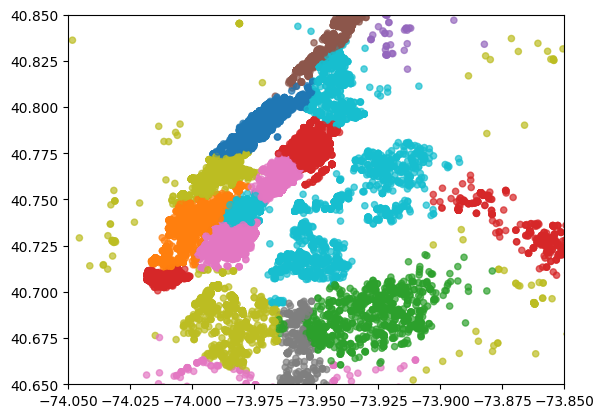

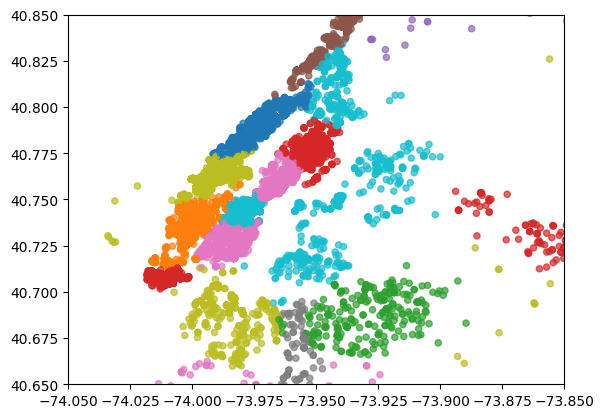

In [ ]:
show_scatterplot(x=train['longitude'], y=train['latitude'], hue=train_pred_gm)
show_scatterplot(x=test['longitude'], y=test['latitude'], hue=test_pred_gm)

In [ ]:
train_gm_X = train_X.copy()
train_gm_X['cluster'] = train_pred_gm
test_gm_X = test_X.copy()
test_gm_X['cluster'] = test_pred_gm

coef_gm = print_metrics(train_gm_X, test_gm_X, 'GaussianMixture Lasso')

Model: GaussianMixture Lasso
Train MAE: 1220.980528482169
Test MAE: 1023.2820395963117
Train RMSE: 24564.215500132414
Test RMSE: 2170.419119869467
Train R2: 0.005745973769317181
Test R2: 0.3402325136540828


In [ ]:
features_cluster = features + ['cluster']
feature_importance_gm = pd.DataFrame({
    'feature': features_cluster,
    'coef': abs(coef_gm)
})
feature_importance_gm = feature_importance_gm.sort_values('coef', ascending=True)
feature_importance_gm

,feature,coef
3,latitude,0.000000
2,longitude,0.000000
16,RoofDeck,55.437889
23,NewConstruction,73.764308
6,CatsAllowed,81.698723
14,Pre-War,83.087301
21,SwimmingPool,131.247233
20,Balcony,150.587047
17,OutdoorSpace,183.899112
10,Dishwasher,184.805875


## 7. New features


In [ ]:
features_cluster = features + ['cluster']
def sort_features(coef):
    df = pd.DataFrame({
    'feature': features_cluster,
    'coef': abs(coef)
})
    df = df.sort_values('coef', ascending=True)
    print(df)

In [ ]:
df_metrics

,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Base Lasso,1224.789156,1023.124293,24565.197313,2173.420621,0.005666,0.338406
1,KMeans Lasso,1223.664108,1021.239459,24565.067464,2172.554432,0.005677,0.338934
2,DBSCAN Lasso,1218.456850,1015.112331,24564.301111,2168.563404,0.005739,0.341360
3,AgglomerativeClustering Lasso,1741.311110,1399.033064,36624.217145,1952.992131,0.003687,0.275191
4,GaussianMixture Lasso,1220.980528,1023.282040,24564.215500,2170.419120,0.005746,0.340233


In [ ]:
new_features = ['bathrooms',  'bedrooms', 'interest_level_encoded']

k_means = KMeans(n_clusters=30, n_init=10, random_state=0)
k_means.fit(train[new_features])

train_pred = k_means.predict(train[new_features])
test_pred = k_means.predict(test[new_features])

train_cluster_X = train_X.copy()
train_cluster_X['cluster'] = train_pred
test_cluster_X = test_X.copy()
test_cluster_X['cluster'] = test_pred

coef_new = print_metrics(train_cluster_X, test_cluster_X, 'KMeans Lasso 2')
sort_features(coef_new)

Model: KMeans Lasso 2
Train MAE: 1225.8910441158057
Test MAE: 1024.431994244422
Train RMSE: 24565.145786355755
Test RMSE: 2175.4183902008135
Train R2: 0.005670664355296284
Test R2: 0.3371896408273989
                   feature          coef
3                 latitude      0.000000
2                longitude      0.000000
23         NewConstruction     23.269356
14                 Pre-War     61.087885
16                RoofDeck     81.526590
6              CatsAllowed     83.117427
21            SwimmingPool     92.149658
10              Dishwasher    183.177292
20                 Balcony    184.839561
17            OutdoorSpace    186.628252
25                 cluster    244.939545
18              DiningRoom    246.548872
7           HardwoodFloors    273.186548
19       HighSpeedInternet    293.734263
11                   NoFee    325.321007
24                 Terrace    413.630135
8              DogsAllowed    504.650257
15           LaundryinUnit    542.087701
5                 Ele

In [ ]:
dbscan = DBSCAN(eps=0.001, min_samples=5)
interest_level_map = {'low': 0, 'medium': 1, 'high': 2}
full_df['interest_level_encoded'] = full_df['interest_level'].map(interest_level_map)
new_features = ['bathrooms',  'bedrooms', 'interest_level_encoded']
pred = dbscan.fit_predict(full_df[new_features])
train_pred_dbscan = pred[:train.shape[0]]
test_pred_dbscan = pred[train.shape[0]:]

train_dbscan_X = train_X.copy()
train_dbscan_X['cluster'] = train_pred_dbscan
test_dbscan_X = test_X.copy()
test_dbscan_X['cluster'] = test_pred_dbscan

coef_dbscan = print_metrics(train_dbscan_X, test_dbscan_X, 'DBSCAN Lasso 2')
sort_features(coef_dbscan)

Model: DBSCAN Lasso 2
Train MAE: 1225.250585702562
Test MAE: 1023.0831700084536
Train RMSE: 24565.039961953917
Test RMSE: 2171.382871783844
Train R2: 0.005679231296558784
Test R2: 0.33964645786057956
                   feature          coef
3                 latitude      0.000000
2                longitude      0.000000
23         NewConstruction     28.433341
14                 Pre-War     58.882063
16                RoofDeck     81.682576
6              CatsAllowed     83.900779
21            SwimmingPool     99.181102
10              Dishwasher    176.386246
20                 Balcony    186.836971
17            OutdoorSpace    188.861934
18              DiningRoom    244.708048
7           HardwoodFloors    269.059548
19       HighSpeedInternet    289.530140
11                   NoFee    330.790133
24                 Terrace    414.631372
8              DogsAllowed    510.642544
15           LaundryinUnit    539.493825
5                 Elevator    587.842298
13           FitnessC

In [ ]:
sample = sample_cluster[new_features]
ac = AgglomerativeClustering(n_clusters=30)
ac.fit(sample)

labels = ac.labels_
sample_data['cluster'] = labels
ac_train_X, ac_test_X, ac_train_y, ac_test_y = train_test_split(
    sample_data, sample_target, test_size=0.2, random_state=42
)

train_x_mms = mms.fit_transform(ac_train_X)
test_x_mms = mms.transform(ac_test_X)

lasso.fit(train_x_mms, ac_train_y)

train_predict = lasso.predict(train_x_mms)
test_predict = lasso.predict(test_x_mms)

metrics_dict = {
    'Model': 'AgglomerativeClustering Lasso 2',
    'Train MAE': mean_absolute_error(ac_train_y, train_predict),
    'Test MAE': mean_absolute_error(ac_test_y, test_predict),
    'Train RMSE': mean_squared_error(ac_train_y, train_predict)**0.5,
    'Test RMSE': mean_squared_error(ac_test_y, test_predict)**0.5,
    'Train R2': r2_score(ac_train_y, train_predict),
    'Test R2': r2_score(ac_test_y, test_predict)
}

for k, v in metrics_dict.items():
    print(f"{k}: {v}")

df_metrics = pd.concat([df_metrics, pd.DataFrame([metrics_dict])], ignore_index=True)

ac_coef = lasso.coef_
sort_features(ac_coef)

Model: AgglomerativeClustering Lasso 2
Train MAE: 953.576247172482
Test MAE: 2051.6802979472236
Train RMSE: 9192.429782858659
Test RMSE: 70955.7595308116
Train R2: 0.03529821566996061
Test R2: 0.0008846136864505416
                   feature          coef
3                 latitude      0.000000
2                longitude      0.000000
21            SwimmingPool      0.374640
23         NewConstruction     35.590709
10              Dishwasher     39.278095
20                 Balcony     75.483715
14                 Pre-War     80.990973
16                RoofDeck     86.596862
6              CatsAllowed     88.769968
13           FitnessCenter    108.545449
7           HardwoodFloors    155.073797
11                   NoFee    186.618278
25                 cluster    211.379921
17            OutdoorSpace    230.078695
19       HighSpeedInternet    231.088268
24                 Terrace    282.366640
8              DogsAllowed    284.998160
18              DiningRoom    288.276543
22    

In [ ]:
gm = GaussianMixture(n_components=30)
gm.fit(train[new_features])

train_pred_gm = gm.predict(train[new_features])
test_pred_gm = gm.predict(test[new_features])

train_gm_X = train_X.copy()
train_gm_X['cluster'] = train_pred_gm
test_gm_X = test_X.copy()
test_gm_X['cluster'] = test_pred_gm

coef_gm = print_metrics(train_gm_X, test_gm_X, 'GaussianMixture Lasso 2')
sort_features(coef_gm)

Model: GaussianMixture Lasso 2
Train MAE: 1220.234892255998
Test MAE: 1019.4221664415585
Train RMSE: 24565.009891543465
Test RMSE: 2166.4134282441482
Train R2: 0.005681665619106657
Test R2: 0.3426655795003841
                   feature          coef
3                 latitude      0.000000
2                longitude      0.000000
23         NewConstruction     32.282388
14                 Pre-War     55.643994
6              CatsAllowed     77.512767
16                RoofDeck     86.478723
21            SwimmingPool    105.629909
10              Dishwasher    175.576416
17            OutdoorSpace    189.690640
20                 Balcony    196.687149
18              DiningRoom    240.976980
7           HardwoodFloors    269.094749
19       HighSpeedInternet    295.626016
11                   NoFee    336.668253
24                 Terrace    409.270230
8              DogsAllowed    509.408768
15           LaundryinUnit    539.311643
5                 Elevator    583.966440
25          

## 8. Scoring


In [ ]:
df_metrics

,Model,Train MAE,Test MAE,Train RMSE,Test RMSE,Train R2,Test R2
0,Base Lasso,1224.789156,1023.124293,24565.197313,2173.420621,0.005666,0.338406
1,KMeans Lasso,1223.664108,1021.239459,24565.067464,2172.554432,0.005677,0.338934
2,DBSCAN Lasso,1218.456850,1015.112331,24564.301111,2168.563404,0.005739,0.341360
3,AgglomerativeClustering Lasso,1741.311110,1399.033064,36624.217145,1952.992131,0.003687,0.275191
4,GaussianMixture Lasso,1220.980528,1023.282040,24564.215500,2170.419120,0.005746,0.340233
5,KMeans Lasso 2,1225.891044,1024.431994,24565.145786,2175.418390,0.005671,0.337190
6,DBSCAN Lasso 2,1225.250586,1023.083170,24565.039962,2171.382872,0.005679,0.339646
7,AgglomerativeClustering Lasso 2,953.576247,2051.680298,9192.429783,70955.759531,0.035298,0.000885
8,GaussianMixture Lasso 2,1220.234892,1019.422166,24565.009892,2166.413428,0.005682,0.342666
